# Books Sales and Ratings

This project looks at book ratings, genres, prices and sales using Pandas and Matplotlib.

Source: [Books Sales and Ratings on Kaggle](https://www.kaggle.com/datasets/thedevastator/books-sales-and-ratings), shared by thedevastator. Downloaded on 21 October 2026.

## 1. Dataset

I chose this dataset because it has a mix of book details and numerical data to compare. It contains 1,070 rows and 15 columns.

The main question is: **which book characteristics are associated with higher sales?**

This notebook starts with the data checks and ratings distribution. The remaining comparisons are outlined below.

## 2. Loading the data

The original CSV is loaded from `data/raw/`. The code finds the project folder whether the notebook is opened from the main folder or the notebooks folder.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({"figure.figsize": (10, 5), "font.size": 11})

ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "data/raw/manifest.json").exists()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the books-sales-analysis project.")
DATA_PATH = ROOT / "data/raw/Books_Data_Clean.csv"
if not DATA_PATH.exists():
    raise FileNotFoundError("Run: python scripts/download_data.py from the project root first.")

print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
raw = pd.read_csv(DATA_PATH)
print(f"Dataset: {raw.shape[0]:,} rows and {raw.shape[1]} columns")

Python: 3.14.6
Pandas: 3.0.6
Dataset: 1,070 rows and 15 columns


## 3. Initial checks

Checking the column names, data types, missing values and summary statistics.

In [2]:
# repr() exposes trailing spaces in column names.
column_audit = pd.DataFrame({
    "column_name": [repr(column) for column in raw.columns],
    "dtype": raw.dtypes.astype(str).to_numpy(),
    "missing_count": raw.isna().sum().to_numpy(),
    "missing_percent": raw.isna().mean().mul(100).round(2).to_numpy(),
    "unique_values": raw.nunique(dropna=True).to_numpy(),
})
display(column_audit)

,column_name,dtype,missing_count,missing_percent,unique_values
0,'index',int64,0,0.00,1070
1,'Publishing Year',float64,1,0.09,150
2,'Book Name',str,23,2.15,1045
3,'Author',str,0,0.00,735
4,'language_code',str,53,4.95,8
5,'Author_Rating',str,0,0.00,4
6,'Book_average_rating',float64,0,0.00,134
7,'Book_ratings_count',int64,0,0.00,1064
8,'genre',str,0,0.00,4
9,'gross sales',float64,0,0.00,831


In [3]:
raw.info()
display(raw.describe(include="all").T)

<class 'pandas.DataFrame'>
RangeIndex: 1070 entries, 0 to 1069
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   index                1070 non-null   int64  
 1   Publishing Year      1069 non-null   float64
 2   Book Name            1047 non-null   str    
 3   Author               1070 non-null   str    
 4   language_code        1017 non-null   str    
 5   Author_Rating        1070 non-null   str    
 6   Book_average_rating  1070 non-null   float64
 7   Book_ratings_count   1070 non-null   int64  
 8   genre                1070 non-null   str    
 9   gross sales          1070 non-null   float64
 10  publisher revenue    1070 non-null   float64
 11  sale price           1070 non-null   float64
 12  sales rank           1070 non-null   int64  
 13  Publisher            1070 non-null   str    
 14  units sold           1070 non-null   int64  
dtypes: float64(5), int64(4), str(6)
memory usage: 125

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
index,1070.0,NaN,NaN,NaN,534.5,309.026698,0.0,267.25,534.5,801.75,1069.0
Publishing Year,1069.0,NaN,NaN,NaN,1971.377923,185.080257,-560.0,1985.0,2003.0,2010.0,2016.0
Book Name,1047,1045,The Awakening,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Author,1070,735,Stephen King,29,NaN,NaN,NaN,NaN,NaN,NaN,NaN
language_code,1017,8,eng,737,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Author_Rating,1070,4,Intermediate,625,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Book_average_rating,1070.0,NaN,NaN,NaN,4.007,0.247244,2.97,3.85,4.015,4.17,4.77
Book_ratings_count,1070.0,NaN,NaN,NaN,94909.913084,31513.242518,27308.0,70398.0,89309.0,113906.5,206792.0
genre,1070,4,genre fiction,822,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gross sales,1070.0,NaN,NaN,NaN,1856.622944,3936.92424,104.94,372.465,809.745,1487.9575,47795.0


In [4]:
print("Exact duplicate rows:", raw.duplicated().sum())
# An exported row index may conceal duplicate records.
content_columns = [column for column in raw.columns if column.strip().lower() != "index"]
print("Duplicate content excluding index:", raw.duplicated(subset=content_columns).sum())
print("Genre counts (including missing):")
display(raw["genre"].value_counts(dropna=False).rename("book_count"))
print("Publishing-year range:")
display(raw["Publishing Year"].agg(["min", "max"]))

Exact duplicate rows: 0
Duplicate content excluding index: 0
Genre counts (including missing):


genre
genre fiction    822
nonfiction       171
fiction           62
children          15
Name: book_count, dtype: int64

Publishing-year range:


min    -560.0
max    2016.0
Name: Publishing Year, dtype: float64

### What I found

- `Publisher ` has a space at the end of its name.
- Some book names, language codes and publishing years are missing.
- The earliest publishing year is negative. It could refer to an ancient work, so it needs checking.
- `index` looks like an exported row number.
- The genre column includes both `fiction` and `genre fiction`.

These observations are recorded in `docs/cleaning_log.md`.

## 4. Cleaning

The original data is kept unchanged, with a separate copy for cleaning.

The column names need tidying, and the missing values and duplicate checks need reviewing before making changes. No values have been changed or rows removed at this stage.

In [5]:
# Work on a copy so the original stays unchanged.
books = raw.copy()

print("Working copy created:", books.shape)

Working copy created: (1070, 15)


## 5. How are book ratings distributed?

A histogram shows how the average ratings are spread across the dataset. This first chart uses the original data. Missing, non-numeric or out-of-range ratings are left out of the chart and counted below.

Ratings excluded from this chart: 0


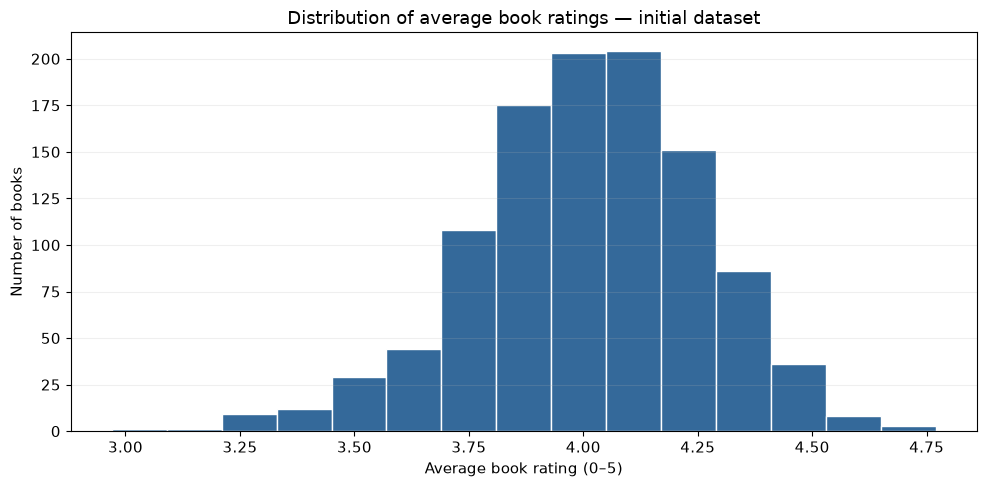

,average_rating
count,1070.000000
mean,4.007000
std,0.247244
min,2.970000
25%,3.850000
50%,4.015000
75%,4.170000
max,4.770000


In [6]:
ratings = pd.to_numeric(raw["Book_average_rating"], errors="coerce")
valid_ratings = ratings[ratings.between(0, 5)]
print("Ratings excluded from this chart:", len(ratings) - len(valid_ratings))

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(valid_ratings, bins=15, color="#34699A", edgecolor="white")
ax.set_title("Distribution of average book ratings — initial dataset")
ax.set_xlabel("Average book rating (0–5)")
ax.set_ylabel("Number of books")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

display(valid_ratings.describe().to_frame("average_rating"))

### Ratings summary

The table above gives the average, median and range of ratings. This is an initial look at the data; the interpretation will follow after the cleaning checks.

## 6. Further analysis

| Question | Comparison | Chart |
| --- | --- | --- |
| How are book ratings distributed? | Rating counts and summary statistics | Histogram |
| Which genres have higher typical sales? | Median units sold and number of books | Bar chart |
| Is there a relationship between ratings and sales? | Ratings against units sold | Scatter plot |
| How do prices vary by genre? | Price summaries for each genre | Box plot |
| How do sales compare across publishers? | Median gross sales, total sales and number of books | Bar chart |

The first chart is above. The following sections are planned comparisons. Group sizes will be included so that small groups aren't overinterpreted.

### Sales by genre

Compare median units sold and the number of books in each genre.

In [7]:
# Compare sales by genre here.

### Ratings and sales

Compare average ratings with units sold using a scatter plot and correlation. A relationship between them would not prove that higher ratings cause more sales.

In [8]:
# Compare ratings and sales here.

### Prices by genre

Compare the typical price and price spread for each genre. The currency needs checking first.

In [9]:
# Compare prices by genre here.

### Sales by publisher

Compare median gross sales, total gross sales and the number of books for each publisher. Book counts matter when comparing publishers with different catalogue sizes.

In [10]:
# Compare sales by publisher here.

## 7. Findings

The initial checks show missing book names, language codes and a publishing year, plus a column name that needs tidying.

Final sales findings and recommendations will follow once the cleaning and comparisons are complete. Any conclusions will be limited to this dataset because its coverage and sales period need checking. Publishing year should not be treated as the year of a sale.